# Gasto público en vivienda

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "gasto-publico-vivienda"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en vivienda"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuánto gastan las administraciones públicas en vivienda, en porcentaje del PIB: el desarrollo de la vivienda (función 06.1 de la clasificación COFOG, p. ej. construcción y promoción de vivienda) y las prestaciones de vivienda (función 10.6, p. ej. ayudas al alquiler).

**Cómo se lee.** Un valor de 0,5 significa que ese gasto equivale al 0,5 % del PIB.

**Limitaciones.**
- No incluye los beneficios fiscales (p. ej. deducciones por vivienda), que no son gasto.
- EE. UU.: la OCDE solo publica las divisiones completas de la COFOG, no estas dos funciones; Canadá no está en su tabla COFOG; y no hay media de la OCDE. Esas series quedan sin dato.

## 2. Descarga

Eurostat `gov_10a_exp` (administraciones públicas `S13`, gasto total `TE`, millones de euros), funciones `GF0601` y `GF1006`, y el PIB a precios corrientes de Eurostat `nama_10_gdp` (`B1GQ`, millones de euros).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta


def descargar():
    partes, fuentes = [], []
    for cofog in ("GF0601", "GF1006"):
        d, fuentes = eurostat.get("gov_10a_exp", {"freq": "A", "unit": "MIO_EUR", "sector": "S13", "na_item": "TE", "cofog99": cofog}, desde=DESDE)
        partes.append(d.assign(concepto=cofog))
    pib, _ = eurostat.get("nama_10_gdp", {"freq": "A", "unit": "CP_MEUR", "na_item": "B1GQ"}, desde=DESDE)
    partes.append(pib.assign(concepto="PIB"))
    return pd.concat(partes, ignore_index=True), fuentes  # una fuente por serie (gov_10a_exp)


publicado, f_euro = descargar()

## 3. Transformación

Se suman las dos funciones en millones de euros y se dividen por el PIB. Se calcula así, y no con el porcentaje que publica Eurostat, porque ese porcentaje viene con un solo decimal y las prestaciones de vivienda de España saldrían como 0,0. Un año en que falte alguna parte queda sin dato.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]

ancho = publicado.pivot_table(index=["serie", "periodo"], columns="concepto", values="valor")
gasto = ancho[["GF0601", "GF1006"]].sum(axis=1, min_count=2)
df = (gasto / ancho["PIB"] * 100).rename("valor").reset_index()[["serie", "periodo", "valor"]]
CODIGO = "gov_10a_exp (GF0601 + GF1006, S13, TE, MIO_EUR) / nama_10_gdp (B1GQ, CP_MEUR)"
fuentes = [FuenteMeta(f.serie, f.organismo, CODIGO, f.url, f.fecha_consulta) for f in f_euro]
COFOG_OCDE = ("OECD", "OECD.SDD.NAD,DSD_NASEC10@DF_TABLE11 (consultada: sin las funciones 06.1 y 10.6)", "https://data-explorer.oecd.org/")
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": COFOG_OCDE, "eeuu": COFOG_OCDE, "canada": COFOG_OCDE})

NOTAS = [
    "Eurostat gov_10a_exp: gasto total de las administraciones públicas en las funciones COFOG 06.1 (desarrollo de la vivienda) y 10.6 (vivienda, protección social), sumadas en millones de euros y divididas por el PIB a precios corrientes (nama_10_gdp). UE-27 de composición actual (EU27_2020).",
    "EE. UU.: la OCDE solo publica las divisiones completas de la COFOG (p. ej. 06, vivienda y servicios comunitarios), no las funciones 06.1 y 10.6. Canadá no está en la tabla COFOG de la OCDE, que tampoco publica una media de sus países. Esas series quedan sin dato.",
    "No incluye los beneficios fiscales a la vivienda, que no se contabilizan como gasto.",
]

## 4. Visualización

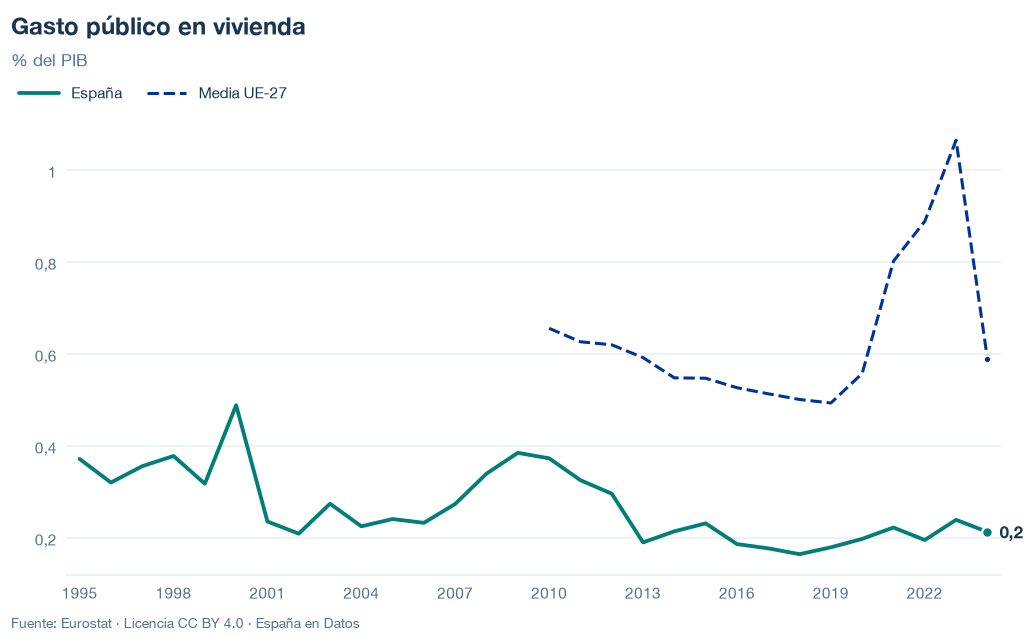

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-publico-vivienda.json y data/gasto-publico-vivienda.csv


## 6. Fuentes, notas y licencia

- Eurostat, `gov_10a_exp` y `nama_10_gdp`.
- OCDE, `DSD_NASEC10@DF_TABLE11` (COFOG), consultada para EE. UU., Canadá y la OCDE.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.